## Import Libraries

In [1]:
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)

## Configuration

In [2]:
# Dataset
DATA_DIR = Path(r"C:\Users\91995\Desktop\AI\AI_Vision\dataset")
CATEGORY = "bottle"

# Image configuration
IMG_SIZE = 256

# Training configuration
BATCH_SIZE = 16
EPOCHS = 100

# Keep the current learning rate
LEARNING_RATE = 0.001

# Reproducibility
SEED = 42

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cpu


In [3]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed:", SEED)

Random seed: 42


## Load the Dataset

In [4]:
train_dir = DATA_DIR / CATEGORY / "train" / "good"
test_dir = DATA_DIR / CATEGORY / "test"

train_images = sorted(
    list(train_dir.glob("*.png"))
)

print("Number of normal training images:", len(train_images))

Number of normal training images: 209


In [5]:
print("Training directory:", train_dir)
print("Directory exists:", train_dir.exists())

Training directory: C:\Users\91995\Desktop\AI\AI_Vision\dataset\bottle\train\good
Directory exists: True


## Data Exploration

In [6]:
# 1. Inspect one of the training images
sample_image = Image.open(train_images[0])

print("Image size:", sample_image.size)
print("Image mode:", sample_image.mode)

Image size: (900, 900)
Image mode: RGB


In [7]:
image_array = np.array(sample_image)

print("Image shape:", image_array.shape)
print("Minimum pixel value:", image_array.min())
print("Maximum pixel value:", image_array.max())
print("Mean pixel value:", image_array.mean())

Image shape: (900, 900, 3)
Minimum pixel value: 29
Maximum pixel value: 255
Mean pixel value: 136.8687646090535


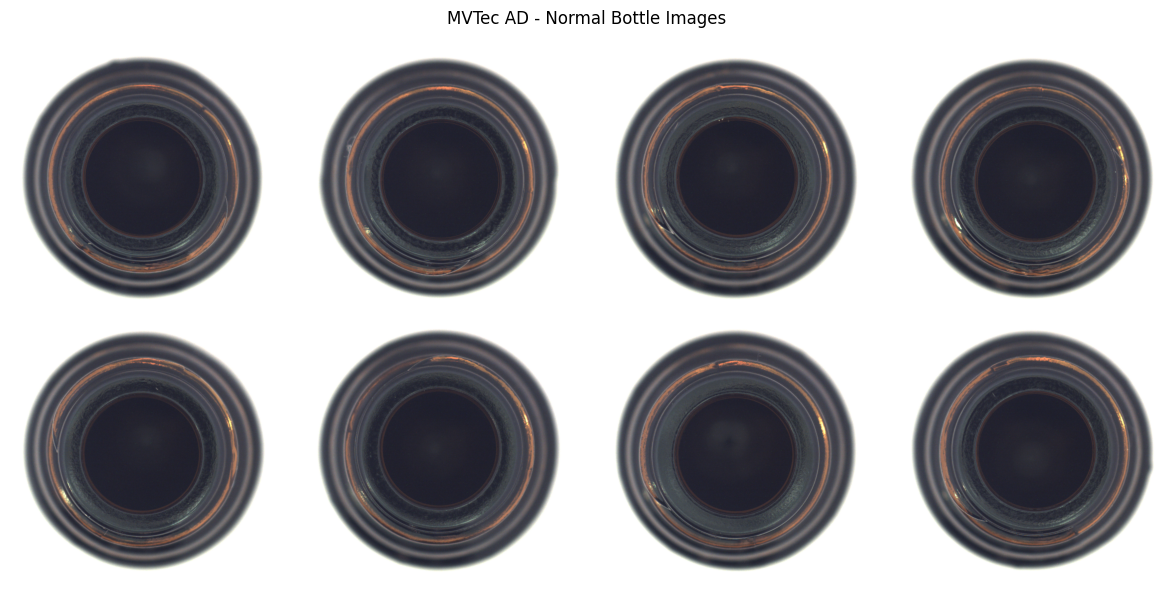

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax, image_path in zip(axes.ravel(), train_images[:8]):
    image = Image.open(image_path)
    ax.imshow(image)
    ax.axis("off")

plt.suptitle("MVTec AD - Normal Bottle Images")
plt.tight_layout()
plt.show()

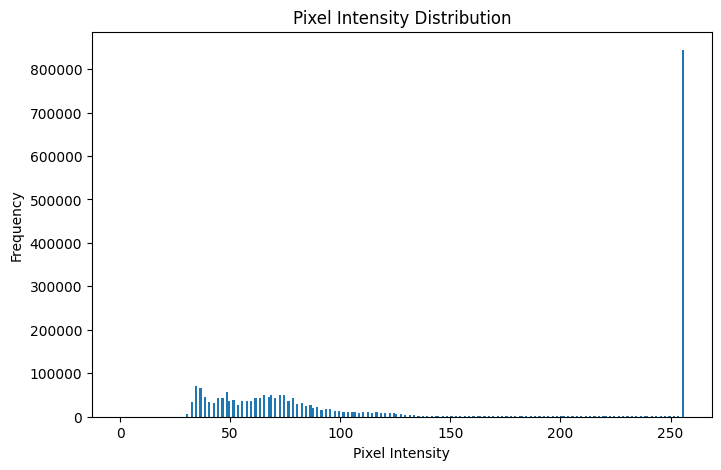

In [9]:
plt.figure(figsize=(8, 5))

plt.hist(
    image_array.ravel(),
    bins=256,
    range=(0, 256)
)

plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.title("Pixel Intensity Distribution")

plt.show()

## Data Preparation

In [10]:
transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

In [11]:
# Train - validation split
train_paths, val_paths = train_test_split(
    train_images,
    test_size=0.20,
    random_state=SEED
)

print("Total normal images:", len(train_images))
print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))

Total normal images: 209
Training images: 167
Validation images: 42


In [12]:
# Creating PyTorch Dataset class for MVTec AD dataset
class MVTecDataset(Dataset):

    def __init__(self, image_paths, transform=None):
        self.image_paths = image_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):

        image_path = self.image_paths[index]

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image

In [13]:
train_dataset = MVTecDataset(
    train_paths,
    transform=transform
)
print("Number of training samples:", len(train_dataset))

val_dataset = MVTecDataset(
    val_paths,
    transform=transform
)
print("Number of validation samples:", len(val_dataset))

Number of training samples: 167
Number of validation samples: 42


In [14]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)
print("Number of training batches:", len(train_loader))

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)
print("Number of validation batches:", len(val_loader))

Number of training batches: 11
Number of validation batches: 3


## Autoencoder Model

The encoder compresses the image into a lower-dimensional representation.
The decoder reconstructs the original image.

The model is trained only on normal products. The assumption is that it
will reconstruct normal products better than defective products.

In [16]:
class ConvAutoencoder(nn.Module):

    def __init__(self):
        super().__init__()

        # Encoder
        self.encoder = nn.Sequential(

            nn.Conv2d(
                3, 32,
                kernel_size=3,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2),

            nn.Conv2d(
                32, 64,
                kernel_size=3,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2),

            nn.Conv2d(
                64, 128,
                kernel_size=3,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2),

            nn.Conv2d(
                128, 256,
                kernel_size=3,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2),

            nn.Conv2d(
                256, 256,
                kernel_size=3,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2)
        )

        # Decoder
        self.decoder = nn.Sequential(

            nn.ConvTranspose2d(
                256, 256,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2),

            nn.ConvTranspose2d(
                256, 128,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2),

            nn.ConvTranspose2d(
                128, 64,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2),

            nn.ConvTranspose2d(
                64, 32,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2),

            nn.ConvTranspose2d(
                32, 3,
                kernel_size=4,
                stride=2,
                padding=1
            ),

            nn.Sigmoid()
        )

    def forward(self, x):

        latent = self.encoder(x)
        reconstruction = self.decoder(latent)

        return reconstruction

In [17]:
model = ConvAutoencoder().to(device)
print(model)

ConvAutoencoder(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.2)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): LeakyReLU(negative_slope=0.2)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (10): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): LeakyReLU(negative_slope=0.2)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=Tru

In [18]:
sample_batch = next(iter(train_loader))
sample_batch = sample_batch.to(device)

with torch.no_grad():
    output = model(sample_batch)

print("Input shape:", sample_batch.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([16, 3, 256, 256])
Output shape: torch.Size([16, 3, 256, 256])


In [19]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Total parameters: 2,719,651
Trainable parameters: 2,719,651


### Model Training

In [91]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

In [ ]:
train_losses = []
val_losses = []

for epoch in range(EPOCHS):

    # -------------------------
    # Training
    # -------------------------
    model.train()

    running_train_loss = 0.0

    for images in train_loader:

        images = images.to(device)

        reconstructed = model(images)

        loss = criterion(
            reconstructed,
            images
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_train_loss += loss.item()

    train_loss = (
        running_train_loss / len(train_loader)
    )

    # -------------------------
    # Validation
    # -------------------------
    model.eval()

    running_val_loss = 0.0

    with torch.no_grad():

        for images in val_loader:

            images = images.to(device)

            reconstructed = model(images)

            loss = criterion(
                reconstructed,
                images
            )

            running_val_loss += loss.item()

    val_loss = (
        running_val_loss / len(val_loader)
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.6f} "
        f"Val Loss: {val_loss:.6f}"
    )

Epoch [1/100] Train Loss: 0.007024 Val Loss: 0.007656
Epoch [2/100] Train Loss: 0.002771 Val Loss: 0.003755
Epoch [3/100] Train Loss: 0.001973 Val Loss: 0.002040


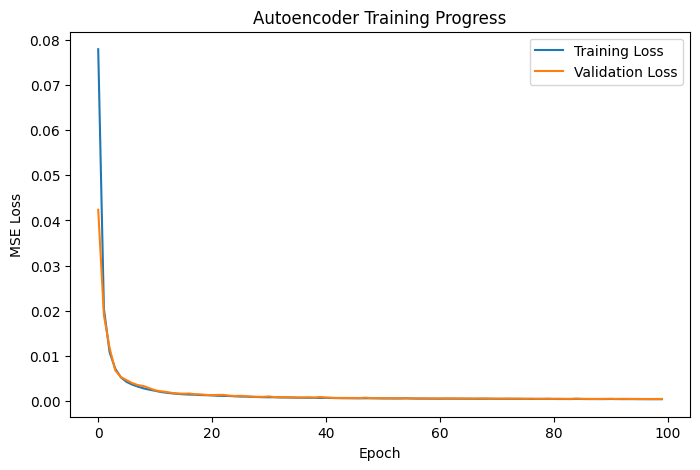

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training Progress")
plt.legend()

plt.show()

### Visualize Reconstruction

In [ ]:
model.eval()

images = next(iter(val_loader))
images = images.to(device)

with torch.no_grad():
    reconstructed = model(images)

images = images.cpu()
reconstructed = reconstructed.cpu()

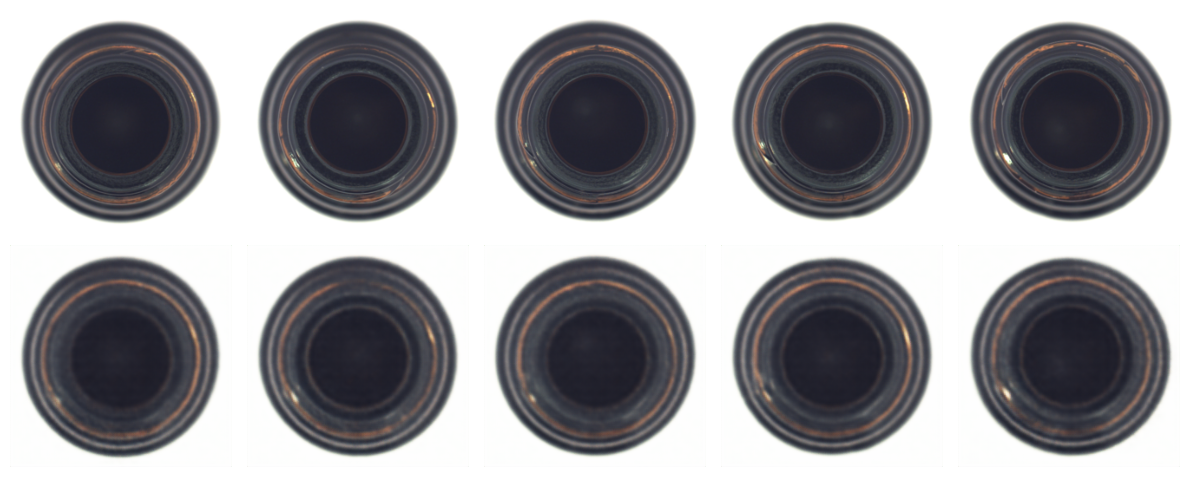

In [ ]:
fig, axes = plt.subplots(
    2, 5,
    figsize=(12, 5)
)

for i in range(5):

    axes[0, i].imshow(
        images[i].permute(1, 2, 0)
    )

    axes[0, i].axis("off")

    axes[1, i].imshow(
        reconstructed[i].permute(1, 2, 0)
    )

    axes[1, i].axis("off")

axes[0, 0].set_ylabel(
    "Original",
    fontsize=12
)

axes[1, 0].set_ylabel(
    "Reconstructed",
    fontsize=12
)

plt.tight_layout()
plt.show()

### Validation Reconstruction error

In [ ]:
def calculate_reconstruction_errors(
    model,
    data_loader,
    device
):

    model.eval()

    errors = []

    with torch.no_grad():

        for images in data_loader:

            images = images.to(device)

            reconstructed = model(images)

            batch_errors = torch.mean(
                (images - reconstructed) ** 2,
                dim=(1, 2, 3)
            )

            errors.extend(
                batch_errors.cpu().numpy()
            )

    return np.array(errors)

In [ ]:
val_errors = calculate_reconstruction_errors(
    model,
    val_loader,
    device
)

print("Validation images:", len(val_errors))
print("Mean error:", val_errors.mean())
print("Median error:", np.median(val_errors))
print("Minimum error:", val_errors.min())
print("Maximum error:", val_errors.max())

Validation images: 42
Mean error: 0.00049839035
Median error: 0.0004824953
Minimum error: 0.00037857486
Maximum error: 0.0007489307


### Anomaly Threshold

In [ ]:
threshold = np.percentile(
    val_errors,
    95
)

print("Anomaly threshold:", threshold)

Anomaly threshold: 0.0006400452402886001


### Testing the Model

In [ ]:
test_good_paths = sorted(
    list(
        (test_dir / "good").glob("*.png")
    )
)

defect_types = [
    "broken_large",
    "broken_small",
    "contamination"
]

test_defect_paths = []

for defect_type in defect_types:

    paths = sorted(
        list(
            (test_dir / defect_type).glob("*.png")
        )
    )

    test_defect_paths.extend(paths)

print("Test good images:", len(test_good_paths))
print("Test defective images:", len(test_defect_paths))

Test good images: 20
Test defective images: 63


In [ ]:
test_good_dataset = MVTecDataset(
    test_good_paths,
    transform=transform
)

test_defect_dataset = MVTecDataset(
    test_defect_paths,
    transform=transform
)

In [ ]:
test_good_loader = DataLoader(
    test_good_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_defect_loader = DataLoader(
    test_defect_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [ ]:
good_errors = calculate_reconstruction_errors(
    model,
    test_good_loader,
    device
)

defect_errors = calculate_reconstruction_errors(
    model,
    test_defect_loader,
    device
)

print("Good test images:", len(good_errors))
print("Defective test images:", len(defect_errors))

Good test images: 20
Defective test images: 63


In [ ]:
y_true = np.concatenate([
    np.zeros(len(good_errors)),
    np.ones(len(defect_errors))
])

y_scores = np.concatenate([
    good_errors,
    defect_errors
])

print("Total test samples:", len(y_true))

Total test samples: 83


In [ ]:
# Calculate AUC-ROC
auroc = roc_auc_score(
    y_true,
    y_scores
)

print(f"Test AUROC: {auroc:.4f}")

Test AUROC: 0.8937


In [ ]:
predictions = (
    y_scores > threshold
).astype(int)

In [ ]:
print(
    classification_report(
        y_true,
        predictions,
        target_names=[
            "Good",
            "Defective"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

        Good       0.59      0.85      0.69        20
   Defective       0.94      0.81      0.87        63

    accuracy                           0.82        83
   macro avg       0.77      0.83      0.78        83
weighted avg       0.86      0.82      0.83        83



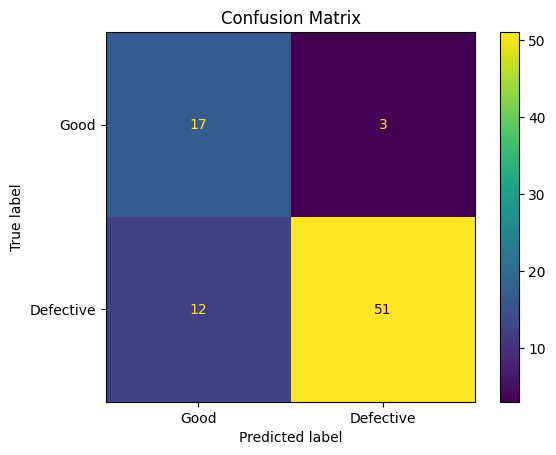

In [ ]:
cm = confusion_matrix(
    y_true,
    predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Good",
        "Defective"
    ]
)

disp.plot()

plt.title("Confusion Matrix")
plt.show()

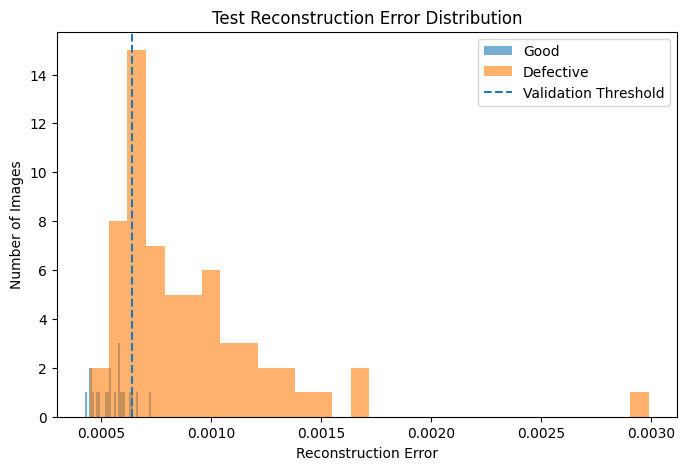

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(
    good_errors,
    bins=30,
    alpha=0.6,
    label="Good"
)

plt.hist(
    defect_errors,
    bins=30,
    alpha=0.6,
    label="Defective"
)

plt.axvline(
    threshold,
    linestyle="--",
    label="Validation Threshold"
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Images")
plt.title("Test Reconstruction Error Distribution")
plt.legend()

plt.show()

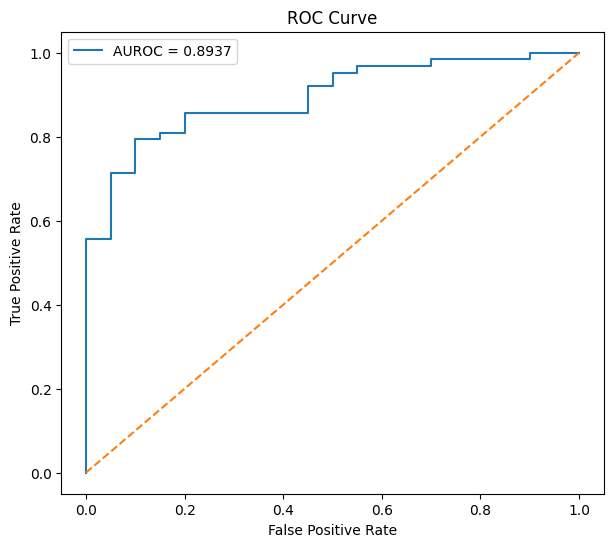

In [ ]:
# ROC Curve
fpr, tpr, _ = roc_curve(
    y_true,
    y_scores
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"AUROC = {auroc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()

plt.show()

In [ ]:
# Anomaly Visualization
model.eval()

images = next(iter(test_defect_loader))
images = images.to(device)

with torch.no_grad():
    reconstructed = model(images)

difference = torch.abs(
    images - reconstructed
)

anomaly_map = difference.mean(
    dim=1
).cpu().numpy()

images = images.cpu()
reconstructed = reconstructed.cpu()

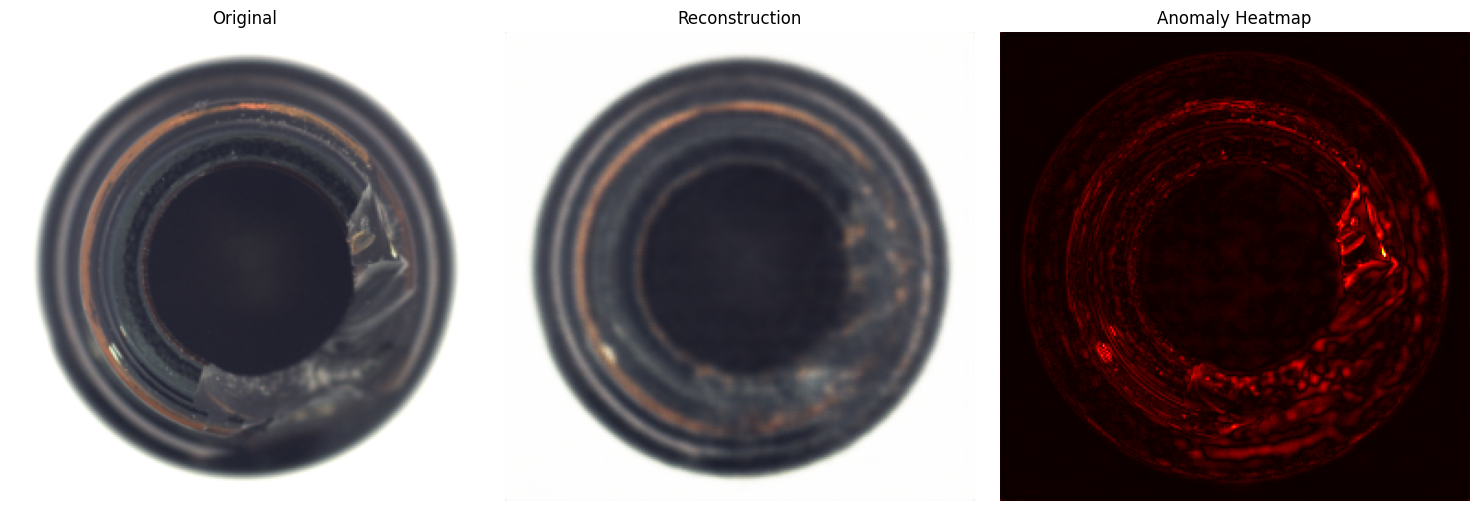

In [ ]:
index = 0

original = images[index].permute(
    1, 2, 0
).numpy()

reconstruction = reconstructed[index].permute(
    1, 2, 0
).numpy()

heatmap = anomaly_map[index]

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5)
)

axes[0].imshow(original)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(reconstruction)
axes[1].set_title("Reconstruction")
axes[1].axis("off")

axes[2].imshow(heatmap, cmap="hot")
axes[2].set_title("Anomaly Heatmap")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
sample_error = defect_errors[0]

prediction = (
    "DEFECTIVE"
    if sample_error > threshold
    else "GOOD"
)

print("Prediction:", prediction)
print(f"Anomaly Score: {sample_error:.6f}")
print(f"Threshold: {threshold:.6f}")

Prediction: DEFECTIVE
Anomaly Score: 0.000658
Threshold: 0.000640


## Motivation for a Feature-Based Approach

The CNN Autoencoder achieved a test AUROC of **0.8937**, demonstrating that reconstruction error provides a strong baseline for unsupervised defect detection.

However, the overlap between normal and defective reconstruction errors indicates that pixel-level reconstruction alone may not capture all visual differences effectively.

To address this limitation, we introduce a feature-based approach using a **pretrained ResNet18**. ResNet provides high-level visual embeddings, allowing anomalies to be detected based on their distance from the feature distribution of normal products.

This provides a complementary approach to the Autoencoder and allows us to evaluate whether high-level feature representations improve anomaly detection performance.

## ResNet18 

A pretrained ResNet18 model is used as a feature extractor. The final ImageNet classification layer is removed so that the network produces high-level visual feature representations instead of class predictions.

In [49]:
from torchvision import models

# Load pretrained ResNet18
resnet = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Remove the final classification layer
feature_extractor = nn.Sequential(
    *list(resnet.children())[:-1]
)

# Move model to the available device
feature_extractor = feature_extractor.to(device)

# Freeze the pretrained model
feature_extractor.eval()

print("ResNet18 feature extractor loaded successfully.")

ResNet18 feature extractor loaded successfully.


In [52]:
# Get the preprocessing configuration associated with the pretrained weights
resnet_weights = models.ResNet18_Weights.DEFAULT

resnet_transform = resnet_weights.transforms()

print(resnet_transform)

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [53]:
resnet_train_dataset = MVTecDataset(
    train_paths,
    transform=resnet_transform
)

resnet_val_dataset = MVTecDataset(
    val_paths,
    transform=resnet_transform
)

In [54]:
resnet_train_loader = DataLoader(
    resnet_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

resnet_val_loader = DataLoader(
    resnet_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [55]:
sample = next(iter(resnet_train_loader))

print("Batch shape:", sample.shape)
print("Minimum value:", sample.min().item())
print("Maximum value:", sample.max().item())

Batch shape: torch.Size([16, 3, 224, 224])
Minimum value: -1.621286153793335
Maximum value: 2.640000104904175


### Build the Normal Feature Space

The ResNet18 model converts each normal bottle image into a 512-dimensional feature embedding.

Since the training dataset contains only normal images, we can represent the normal feature space using the mean embedding.

This mean embedding acts as a reference point for normal bottles.

For a new image:

- Close to the normal feature center → likely normal
- Far from the normal feature center → potentially defective

We will use Euclidean distance as the anomaly score.

In [ ]:
def extract_embeddings(model, data_loader, device):
    model.eval()

    embeddings = []

    with torch.no_grad():
        for images in data_loader:
            images = images.to(device)

            features = model(images)

            # Convert [batch, 512, 1, 1] → [batch, 512]
            features = features.flatten(start_dim=1)

            embeddings.append(features.cpu().numpy())

    return np.concatenate(embeddings)

In [ ]:
train_embeddings = extract_embeddings(
    feature_extractor,
    resnet_train_loader,
    device
)

print("Training embeddings shape:", train_embeddings.shape)

Training embeddings shape: (167, 512)


In [ ]:
### Define Normal Feature Space

normal_feature_center = np.mean(
    train_embeddings,
    axis=0
)

print(
    "Normal feature center shape:",
    normal_feature_center.shape
)

In [ ]:
### Calculate Feature Distances

from sklearn.metrics import pairwise_distances

def calculate_feature_scores(
    embeddings,
    feature_center
):
    return pairwise_distances(
        embeddings,
        feature_center.reshape(1, -1),
        metric="euclidean"
    ).ravel()

In [ ]:
### Determine ResNet Anomaly Threshold

val_embeddings = extract_embeddings(
    feature_extractor,
    resnet_val_loader,
    device
)

val_feature_scores = calculate_feature_scores(
    val_embeddings,
    normal_feature_center
)

resnet_threshold = np.percentile(
    val_feature_scores,
    95
)

print(f"ResNet validation threshold: {resnet_threshold:.6f}")

### ResNet 

In [ ]:
test_good_paths = list(
    (DATA_DIR / CATEGORY / "test" / "good").glob("*")
)

test_defect_paths = []

for defect_type in defect_types:
    defect_dir = DATA_DIR / CATEGORY / "test" / defect_type

    test_defect_paths.extend(
        list(defect_dir.glob("*"))
    )

print("Test good images:", len(test_good_paths))
print("Test defective images:", len(test_defect_paths))

Test good images: 20
Test defective images: 63


In [ ]:
resnet_test_good_dataset = MVTecDataset(
    test_good_paths,
    transform=resnet_transform
)

resnet_test_defect_dataset = MVTecDataset(
    test_defect_paths,
    transform=resnet_transform
)

In [ ]:
resnet_test_good_loader = DataLoader(
    resnet_test_good_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

resnet_test_defect_loader = DataLoader(
    resnet_test_defect_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [ ]:
test_good_embeddings = extract_embeddings(
    feature_extractor,
    resnet_test_good_loader,
    device
)

test_defect_embeddings = extract_embeddings(
    feature_extractor,
    resnet_test_defect_loader,
    device
)

print("Good embeddings:", test_good_embeddings.shape)
print("Defective embeddings:", test_defect_embeddings.shape)

Good embeddings: (20, 512)
Defective embeddings: (63, 512)


In [ ]:
# Cal Test Anomaly score
test_good_scores = calculate_feature_scores(
    test_good_embeddings,
    normal_feature_center
)

test_defect_scores = calculate_feature_scores(
    test_defect_embeddings,
    normal_feature_center
)

print("TEST - GOOD")
print("------------------------------")
print(f"Mean:   {test_good_scores.mean():.6f}")
print(f"Median: {np.median(test_good_scores):.6f}")
print(f"Min:    {test_good_scores.min():.6f}")
print(f"Max:    {test_good_scores.max():.6f}")

print()

print("TEST - DEFECTIVE")
print("------------------------------")
print(f"Mean:   {test_defect_scores.mean():.6f}")
print(f"Median: {np.median(test_defect_scores):.6f}")
print(f"Min:    {test_defect_scores.min():.6f}")
print(f"Max:    {test_defect_scores.max():.6f}")

TEST - GOOD
------------------------------
Mean:   4.031281
Median: 3.791499
Min:    3.016203
Max:    7.682035

TEST - DEFECTIVE
------------------------------
Mean:   9.171593
Median: 8.574451
Min:    4.154290
Max:    15.013164


In [ ]:
# ResNet AUROC
y_true_resnet = np.concatenate([
    np.zeros(len(test_good_scores)),
    np.ones(len(test_defect_scores))
])

y_scores_resnet = np.concatenate([
    test_good_scores,
    test_defect_scores
])

resnet_auroc = roc_auc_score(
    y_true_resnet,
    y_scores_resnet
)

print(f"ResNet Feature-Based Test AUROC: {resnet_auroc:.4f}")

ResNet Feature-Based Test AUROC: 0.9754


In [ ]:
# Validation THreshold
resnet_predictions = (
    y_scores_resnet > resnet_threshold
).astype(int)

In [ ]:
# Classification report
print(
    classification_report(
        y_true_resnet,
        resnet_predictions,
        target_names=["Good", "Defective"]
    )
)

              precision    recall  f1-score   support

        Good       0.58      0.95      0.72        20
   Defective       0.98      0.78      0.87        63

    accuracy                           0.82        83
   macro avg       0.78      0.86      0.79        83
weighted avg       0.88      0.82      0.83        83



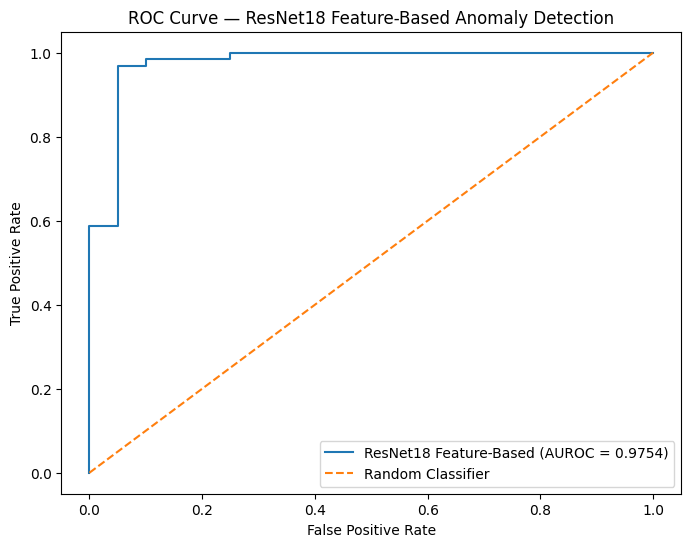

In [ ]:
fpr, tpr, thresholds = roc_curve(
    y_true_resnet,
    y_scores_resnet
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"ResNet18 Feature-Based (AUROC = {resnet_auroc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — ResNet18 Feature-Based Anomaly Detection")
plt.legend()
plt.show()

## Model Comparision

In [2]:
model_names = [
    "CNN Autoencoder",
    "ResNet18 Feature-Based"
]

auroc_scores = [
    0.8937,
    0.9754
]

plt.figure(figsize=(8, 5))

plt.bar(
    model_names,
    auroc_scores
)

plt.ylabel("Test AUROC")
plt.title("Anomaly Detection Model Comparison")

plt.ylim(0, 1)

for i, score in enumerate(auroc_scores):
    plt.text(
        i,
        score + 0.02,
        f"{score:.4f}",
        ha="center"
    )

plt.show()

NameError: name 'plt' is not defined